# Pet Disease Classifier (v5) — Small Dataset Strategy

**17 classes, ~60 images/class.** Uses EfficientNetB0 frozen features + heavy augmentation.

**Key insight:** With only ~60 images per class, fine-tuning the base model causes overfitting.
Instead, we freeze the pretrained base entirely and only train the classification head.

In [41]:
import os, json, random, shutil
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print('TF:', tf.__version__, '| GPU:', len(tf.config.list_physical_devices('GPU')) > 0)

BASE_PATH = './'
INPUT_PATH = './datasets/'
IMG_SIZE = (224, 224)
BATCH_SIZE = 16  # Smaller batch for small dataset

TF: 2.16.1 | GPU: False


In [42]:
PET_RAW = f'{INPUT_PATH}/pet-disease-images'

if os.path.exists(PET_RAW):
    contents = sorted(os.listdir(PET_RAW))
    print(f'Found {len(contents)} folders')
    for c in contents:
        p = os.path.join(PET_RAW, c)
        if os.path.isdir(p):
            print(f'  {c}: {len(os.listdir(p))} files')
else:
    print(f'NOT FOUND: {PET_RAW}')
    print(f'Available: {os.listdir(INPUT_PATH) if os.path.exists(INPUT_PATH) else "INPUT_PATH not found"}')

Found 22 folders
  Dental Disease in Cat: 74 files
  Dental Disease in Dog: 82 files
  Distemper in Dog: 55 files
  Ear Mites in Cat: 63 files
  Eye Infection in Cat: 80 files
  Eye Infection in Dog: 66 files
  Feline Leukemia: 60 files
  Feline Panleukopenia: 57 files
  Fungal Infection in Cat: 78 files
  Fungal Infection in Dog: 79 files
  Hot Spots in Dog: 91 files
  Kennel Cough in Dog: 75 files
  Mange in Dog: 70 files
  Parvovirus in Dog: 79 files
  Ringworm in Cat: 65 files
  Scabies in Cat: 74 files
  Skin Allergy in Cat: 91 files
  Skin Allergy in Dog: 96 files
  Tick Infestation in Dog: 74 files
  Urinary Tract Infection in Cat: 58 files
  Worm Infection in Cat: 93 files
  Worm Infection in Dog: 89 files


In [43]:
def validate_and_clean_images(root_path):
    valid_ext = ('.jpg', '.jpeg', '.png', '.bmp')
    removed = 0
    for root, dirs, files in os.walk(root_path):
        for file in files:
            fp = os.path.join(root, file)
            if not file.lower().endswith(valid_ext):
                try: os.remove(fp); removed += 1
                except: pass
                continue
            try:
                img = tf.io.read_file(fp)
                tf.image.decode_image(img, channels=3)
            except:
                try: os.remove(fp); removed += 1
                except: pass
    return removed

if os.path.exists(PET_RAW):
    r = validate_and_clean_images(PET_RAW)
    print(f'Removed {r} corrupted images')

Removed 0 corrupted images


In [44]:
PET_CLEAN = f'{BASE_PATH}/pet_clean'

PET_MAP = {
    'dental': 'dental_disease', 'distemper': 'distemper',
    'ear': 'ear_infection', 'eye': 'eye_infection',
    'feline leukemia': 'feline_leukemia',
    'feline panleukopenia': 'feline_panleukopenia',
    'fungal': 'fungal_infection', 'hot spots': 'hot_spots',
    'kennel cough': 'kennel_cough', 'mange': 'mange',
    'parvovirus': 'parvovirus', 'ringworm': 'ringworm',
    'scabies': 'scabies', 'skin allergy': 'skin_allergy',
    'tick': 'tick_infestation', 'urinary': 'urinary_infection',
    'worm': 'worm_infection'
}

def normalize_pet_class(name):
    name = name.lower()
    for k, v in PET_MAP.items():
        if k in name: return v
    return None

if os.path.exists(PET_RAW):
    for raw_class in os.listdir(PET_RAW):
        src = os.path.join(PET_RAW, raw_class)
        if not os.path.isdir(src): continue
        clean = normalize_pet_class(raw_class)
        if clean is None:
            print(f'  SKIP: {raw_class}')
            continue
        imgs = [f for f in os.listdir(src) if f.lower().endswith(('.jpg','.jpeg','.png','.bmp'))]
        if not imgs: continue

        random.seed(42)
        random.shuffle(imgs)
        nt = int(len(imgs) * 0.7)
        nv = int(len(imgs) * 0.15)

        for split, il in [('train', imgs[:nt]), ('valid', imgs[nt:nt+nv]), ('test', imgs[nt+nv:])]:
            dst = f'{PET_CLEAN}/{split}/{clean}'
            os.makedirs(dst, exist_ok=True)
            for im in il:
                try: shutil.copy2(os.path.join(src, im), os.path.join(dst, im))
                except: pass

        print(f'  {raw_class} -> {clean}: {len(imgs)} (train={nt}, val={nv}, test={len(imgs)-nt-nv})')

for split in ['train', 'valid', 'test']:
    sp = f'{PET_CLEAN}/{split}'
    if os.path.exists(sp):
        total = 0
        print(f'\n{split.upper()}:')
        for cls in sorted(os.listdir(sp)):
            cp = f'{sp}/{cls}'
            if os.path.isdir(cp):
                c = len(os.listdir(cp))
                total += c
                print(f'  {cls:25s}: {c:4d}')
        print(f'  {"TOTAL":25s}: {total:4d}')

  Dental Disease in Cat -> dental_disease: 74 (train=51, val=11, test=12)
  Dental Disease in Dog -> dental_disease: 82 (train=57, val=12, test=13)
  Distemper in Dog -> distemper: 55 (train=38, val=8, test=9)
  Ear Mites in Cat -> ear_infection: 63 (train=44, val=9, test=10)
  Eye Infection in Cat -> eye_infection: 80 (train=56, val=12, test=12)
  Eye Infection in Dog -> eye_infection: 66 (train=46, val=9, test=11)
  Feline Leukemia -> feline_leukemia: 60 (train=42, val=9, test=9)
  Feline Panleukopenia -> feline_panleukopenia: 57 (train=39, val=8, test=10)
  Fungal Infection in Cat -> fungal_infection: 78 (train=54, val=11, test=13)
  Fungal Infection in Dog -> fungal_infection: 79 (train=55, val=11, test=13)
  Hot Spots in Dog -> hot_spots: 91 (train=63, val=13, test=15)
  Kennel Cough in Dog -> kennel_cough: 75 (train=52, val=11, test=12)
  Mange in Dog -> mange: 70 (train=49, val=10, test=11)
  Parvovirus in Dog -> parvovirus: 79 (train=55, val=11, test=13)
  Ringworm in Cat -> ri

In [45]:
# ============================================================================
# HEAVY AUGMENTATION — critical for small datasets
#
# With only ~60 images per class, we need aggressive augmentation to
# create enough variation so the model doesn't memorize.
# ============================================================================

def augment_image(image, label):
    """Apply heavy augmentation to a single image."""
    # Random horizontal flip
    image = tf.image.random_flip_left_right(image)
    
    # Random brightness, contrast, saturation, hue
    image = tf.image.random_brightness(image, max_delta=0.3)
    image = tf.image.random_contrast(image, lower=0.7, upper=1.3)
    image = tf.image.random_saturation(image, lower=0.7, upper=1.3)
    image = tf.image.random_hue(image, max_delta=0.1)
    
    # Random rotation (up to 30 degrees)
    angle = tf.random.uniform([], -0.5, 0.5)  # radians
    image = tf.image.rot90(image, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    
    # Random zoom via crop and resize
    scale = tf.random.uniform([], 0.8, 1.0)
    h = tf.cast(tf.cast(tf.shape(image)[0], tf.float32) * scale, tf.int32)
    w = tf.cast(tf.cast(tf.shape(image)[1], tf.float32) * scale, tf.int32)
    image = tf.image.random_crop(image, [h, w, 3])
    image = tf.image.resize(image, [224, 224])
    
    # Clip to valid range
    image = tf.clip_by_value(image, 0.0, 255.0)
    
    return image, label

print('Augmentation function defined')

Augmentation function defined


In [46]:
# ============================================================================
# MODEL — EfficientNetB0 with frozen base
#
# EfficientNetB0 includes built-in preprocessing (rescaling to [0,1]),
# so we do NOT need a separate Rescaling layer.
# We feed raw [0, 255] images directly.
# ============================================================================

def create_model(num_classes):
    # EfficientNetB0 has built-in rescaling
    base_model = EfficientNetB0(
        input_shape=(224, 224, 3),
        include_top=False,
        weights='imagenet'
    )
    # FREEZE ENTIRELY — do not fine-tune with this little data
    base_model.trainable = False

    inputs = layers.Input(shape=(224, 224, 3))
    
    # EfficientNetB0 handles preprocessing internally
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation='relu',
                     kernel_regularizer=keras.regularizers.l2(0.005))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs, name='pet_model')

print('EfficientNetB0 model defined (base FROZEN, head trainable)')
print('No separate Rescaling needed — EfficientNetB0 handles it internally')

EfficientNetB0 model defined (base FROZEN, head trainable)
No separate Rescaling needed — EfficientNetB0 handles it internally


In [47]:
# Load raw datasets
train_raw = keras.utils.image_dataset_from_directory(
    f'{PET_CLEAN}/train', image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', shuffle=True, seed=42
)
val_pet = keras.utils.image_dataset_from_directory(
    f'{PET_CLEAN}/valid', image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', shuffle=False
)
test_pet = keras.utils.image_dataset_from_directory(
    f'{PET_CLEAN}/test', image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', shuffle=False
)

pet_class_names = train_raw.class_names
NUM_PET_CLASSES = len(pet_class_names)
print(f'{NUM_PET_CLASSES} classes: {pet_class_names}')

with open(f'{BASE_PATH}/pet_classes.json', 'w') as f:
    json.dump(pet_class_names, f, indent=2)

# Apply heavy augmentation to training set
AUTOTUNE = tf.data.AUTOTUNE
train_pet = train_raw.unbatch().map(augment_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)
train_pet = train_pet.prefetch(AUTOTUNE)
val_pet = val_pet.cache().prefetch(AUTOTUNE)
test_pet = test_pet.cache().prefetch(AUTOTUNE)

print('Training data: augmented on-the-fly (different augmentation each epoch)')
print('Validation/Test: cached, no augmentation')

Found 1007 files belonging to 17 classes.
Found 226 files belonging to 17 classes.
Found 259 files belonging to 17 classes.
17 classes: ['dental_disease', 'distemper', 'ear_infection', 'eye_infection', 'feline_leukemia', 'feline_panleukopenia', 'fungal_infection', 'hot_spots', 'kennel_cough', 'mange', 'parvovirus', 'ringworm', 'scabies', 'skin_allergy', 'tick_infestation', 'urinary_infection', 'worm_infection']
Training data: augmented on-the-fly (different augmentation each epoch)
Validation/Test: cached, no augmentation


In [48]:
# Verify pipeline
for images, labels in train_pet.take(1):
    print(f'Batch: {images.shape}, pixels: [{images.numpy().min():.0f}, {images.numpy().max():.0f}]')
    print(f'Labels: {labels.shape}, sum: {labels[0].numpy().sum():.1f}')

m = create_model(NUM_PET_CLASSES)
for images, labels in val_pet.take(1):
    o = m(images[:1], training=False)
    print(f'Output: {o.shape}, sum: {o.numpy().sum():.4f}, range: [{o.numpy().min():.4f}, {o.numpy().max():.4f}]')
del m
print('Pipeline OK!')

Batch: (16, 224, 224, 3), pixels: [0, 255]
Labels: (16, 17), sum: 1.0
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Output: (1, 17), sum: 1.0000, range: [0.0190, 0.1240]
Pipeline OK!


In [49]:
class_counts = {}
for cn in pet_class_names:
    cd = os.path.join(PET_CLEAN, 'train', cn)
    if os.path.exists(cd):
        class_counts[cn] = len([f for f in os.listdir(cd)
                                if f.lower().endswith(('.jpg','.jpeg','.png','.bmp'))])

total = sum(class_counts.values())
nc = len(class_counts)

pet_weight_dict = {}
for idx, cn in enumerate(pet_class_names):
    c = class_counts.get(cn, 1)
    pet_weight_dict[idx] = round(total / (nc * c), 4)

for idx, cn in enumerate(pet_class_names):
    print(f'  {cn:25s}: {class_counts.get(cn,0):4d} imgs, w={pet_weight_dict[idx]:.3f}')

  dental_disease           :   91 imgs, w=0.651
  distemper                :   38 imgs, w=1.559
  ear_infection            :   44 imgs, w=1.346
  eye_infection            :   80 imgs, w=0.740
  feline_leukemia          :   42 imgs, w=1.410
  feline_panleukopenia     :   39 imgs, w=1.519
  fungal_infection         :   84 imgs, w=0.705
  hot_spots                :   63 imgs, w=0.940
  kennel_cough             :   52 imgs, w=1.139
  mange                    :   49 imgs, w=1.209
  parvovirus               :   55 imgs, w=1.077
  ringworm                 :   45 imgs, w=1.316
  scabies                  :   51 imgs, w=1.161
  skin_allergy             :  100 imgs, w=0.592
  tick_infestation         :   51 imgs, w=1.161
  urinary_infection        :   40 imgs, w=1.481
  worm_infection           :   83 imgs, w=0.714


In [50]:
pet_model = create_model(NUM_PET_CLASSES)
pet_model.summary()

Model: "pet_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 17)             │         4,369 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,386,996 (16.74 MB)

 Trainable params: 334,865 (1.28 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [51]:
# ============================================================================
# TRAINING: HEAD-ONLY (base stays frozen throughout)
#
# With ~60 images/class, fine-tuning the base model always leads to
# overfitting. The pretrained EfficientNetB0 features are already
# excellent — we just need to train a good classifier head on top.
#
# We train for up to 50 epochs with early stopping.
# ============================================================================

print('Training: HEAD ONLY (EfficientNetB0 base frozen)\n')

pet_model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=4, min_lr=1e-6, verbose=1
    )
]

history = pet_model.fit(
    train_pet, validation_data=val_pet,
    epochs=50, class_weight=pet_weight_dict,
    callbacks=callbacks, verbose=1
)

best_val = max(history.history['val_accuracy'])
print(f'\nBest val_accuracy: {best_val:.4f}')

Training: HEAD ONLY (EfficientNetB0 base frozen)

Epoch 1/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 34s 386ms/step - accuracy: 0.1460 - loss: 5.6238 - val_accuracy: 0.3186 - val_loss: 4.5112 - learning_rate: 0.0010
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 324ms/step - accuracy: 0.2880 - loss: 4.7183 - val_accuracy: 0.3451 - val_loss: 4.3195 - learning_rate: 0.0010
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 323ms/step - accuracy: 0.3486 - loss: 4.3560 - val_accuracy: 0.3628 - val_loss: 4.1657 - learning_rate: 0.0010
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 309ms/step - accuracy: 0.4042 - loss: 4.1079 - val_accuracy: 0.3540 - val_loss: 4.0968 - learning_rate: 0.0010
Epoch 5/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 311ms/step - accuracy: 0.4022 - loss: 3.9425 - val_accuracy: 0.3805 - val_loss: 4.0125 - learning_rate: 0.0010
Epoch 6/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 315ms/step - accuracy: 0.4687 - loss: 3.6872 - val_accuracy: 0.3805 - val_loss: 4.0114 - learning_rate: 0.0010
Epoch 7/50
63/63 ━━━━━━━━━━━━━━━

In [52]:
test_loss, test_accuracy = pet_model.evaluate(test_pet, verbose=1)
print(f'\nTest Accuracy: {test_accuracy:.4f}')

# Get predictions
y_true, y_pred_probs = [], []
for images, labels in test_pet:
    preds = pet_model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
y_pred = np.argmax(y_pred_probs, axis=1)

# Top-1 accuracy
top1_acc = np.mean(y_true == y_pred)
print(f'Top-1 Accuracy: {top1_acc:.4f}')

# Top-3 accuracy (correct class is in model's top 3 predictions)
top3_preds = np.argsort(y_pred_probs, axis=1)[:, -3:]
top3_correct = np.array([y_true[i] in top3_preds[i] for i in range(len(y_true))])
top3_acc = np.mean(top3_correct)
print(f'Top-3 Accuracy: {top3_acc:.4f}')

# Top-5 accuracy
top5_preds = np.argsort(y_pred_probs, axis=1)[:, -5:]
top5_correct = np.array([y_true[i] in top5_preds[i] for i in range(len(y_true))])
top5_acc = np.mean(top5_correct)
print(f'Top-5 Accuracy: {top5_acc:.4f}')

print('\nClassification Report:')
print(classification_report(y_true, y_pred, target_names=pet_class_names, zero_division=0))

17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 474ms/step - accuracy: 0.4788 - loss: 2.5865

Test Accuracy: 0.4788
Top-1 Accuracy: 0.4788
Top-3 Accuracy: 0.6680
Top-5 Accuracy: 0.7568

Classification Report:
                      precision    recall  f1-score   support

      dental_disease       0.75      0.62      0.68        24
           distemper       0.24      0.44      0.31         9
       ear_infection       0.56      0.50      0.53        10
       eye_infection       0.60      0.43      0.50        21
     feline_leukemia       0.36      0.56      0.43         9
feline_panleukopenia       0.71      0.50      0.59        10
    fungal_infection       0.50      0.12      0.19        25
           hot_spots       0.50      0.73      0.59        15
        kennel_cough       0.33      0.42      0.37        12
               mange       0.58      0.64      0.61        11
          parvovirus       0.33      0.23      0.27        13
            ringworm       0.39      0.64      0.48        11
  

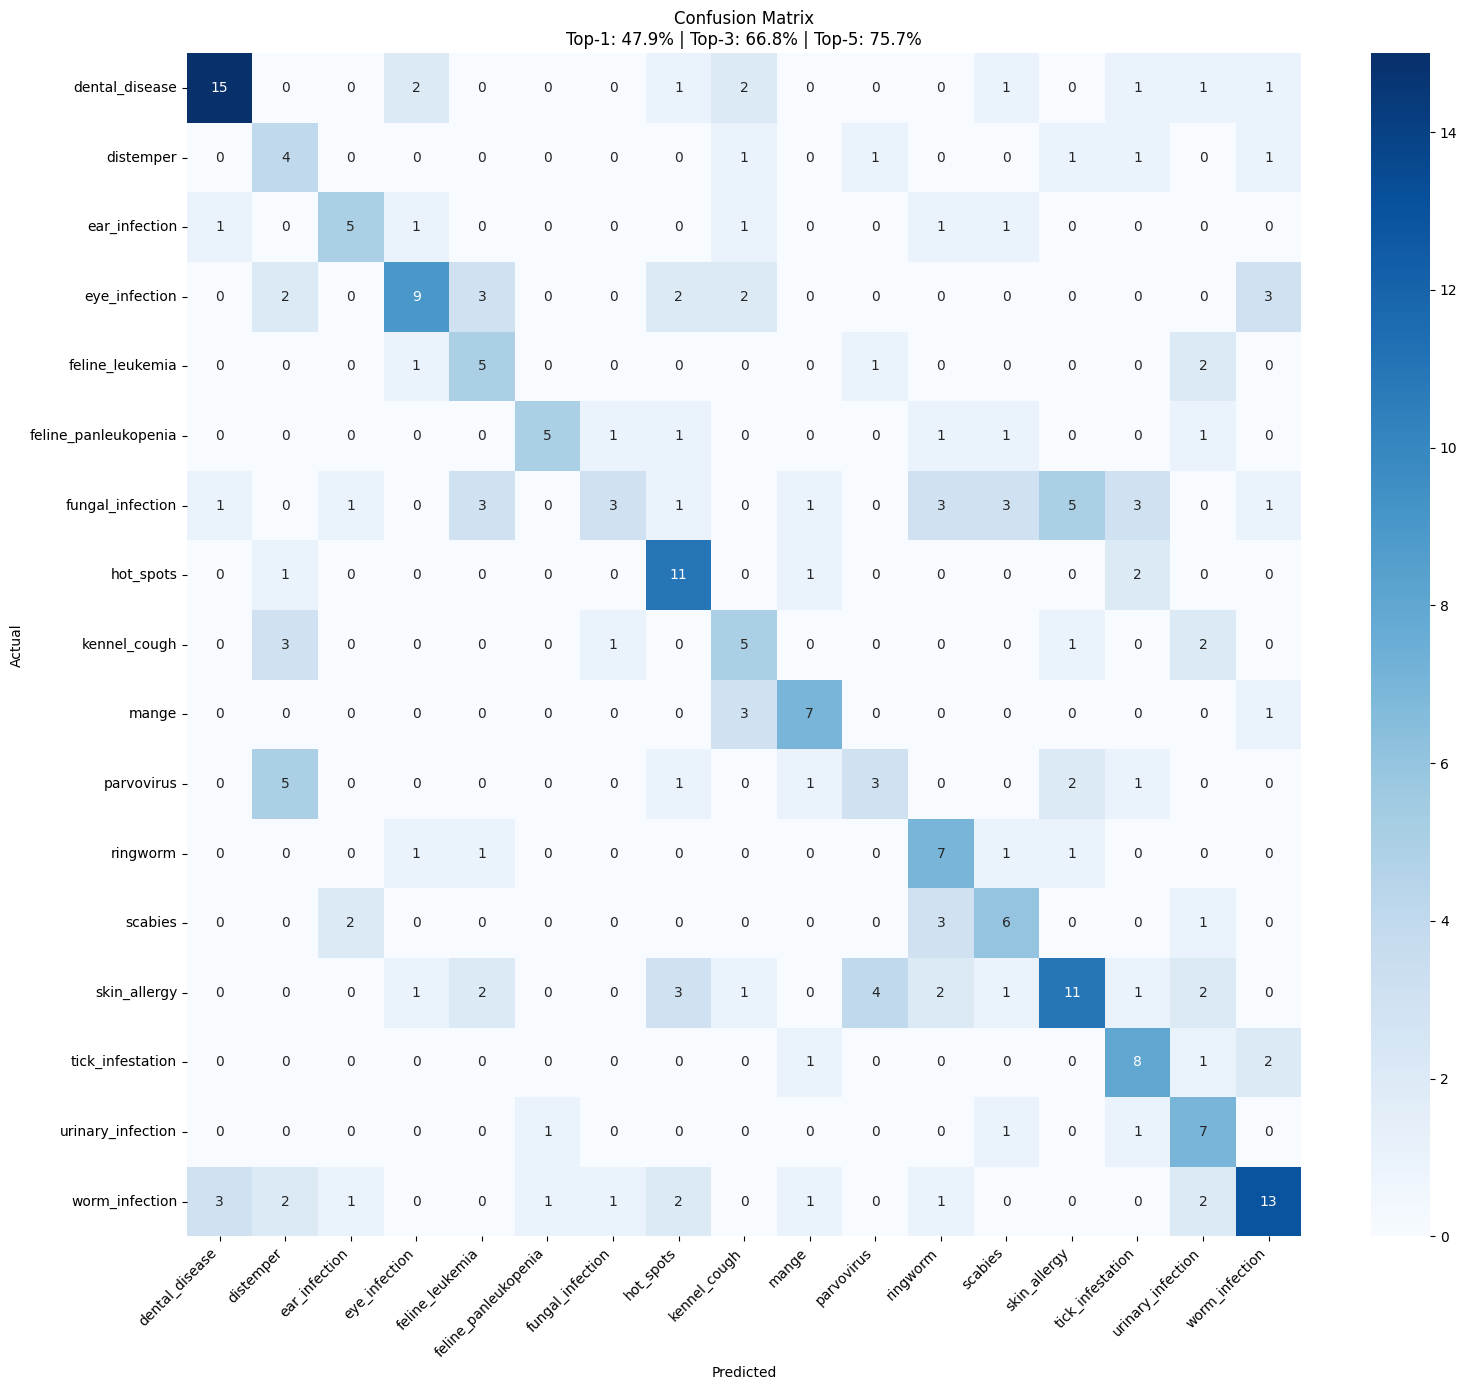

In [53]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(16, 14))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=pet_class_names, yticklabels=pet_class_names)
plt.title(f'Confusion Matrix\nTop-1: {top1_acc:.1%} | Top-3: {top3_acc:.1%} | Top-5: {top5_acc:.1%}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(f'{BASE_PATH}/pet_confusion_matrix.png', dpi=150)
plt.show()

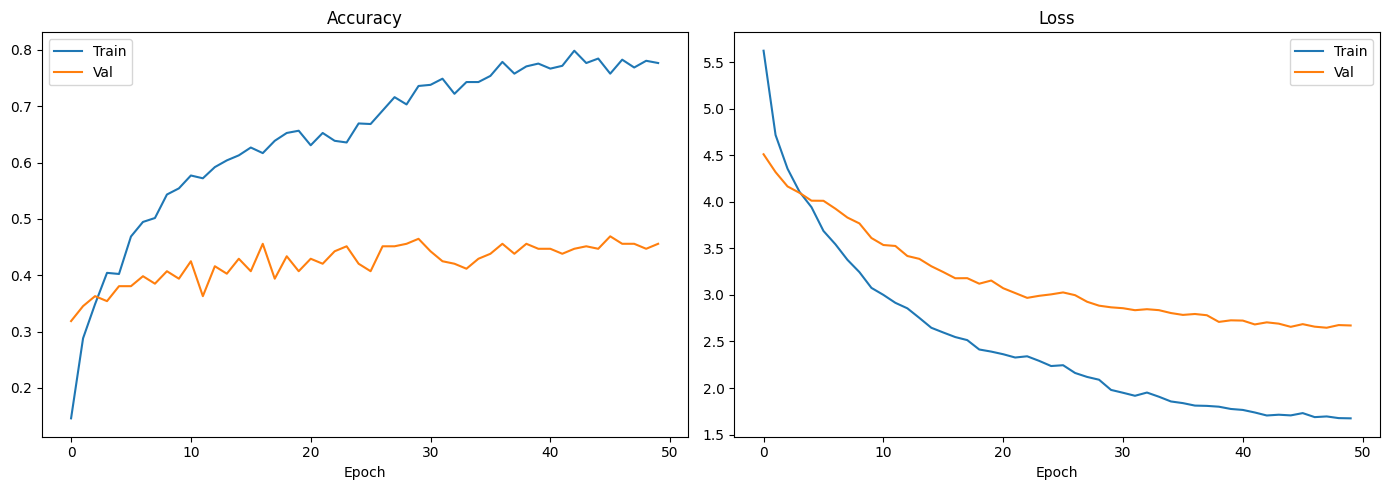

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Val')
axes[0].set_title('Accuracy'); axes[0].legend()
axes[0].set_xlabel('Epoch')

axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Val')
axes[1].set_title('Loss'); axes[1].legend()
axes[1].set_xlabel('Epoch')

plt.tight_layout()
plt.savefig(f'{BASE_PATH}/pet_training_history.png', dpi=150)
plt.show()

In [55]:
MODEL_PATH = f'{BASE_PATH}/pet_skin_multiclass.keras'

pet_model.save(MODEL_PATH)
print(f'Model saved: {MODEL_PATH}')

loaded = keras.models.load_model(MODEL_PATH, compile=False)
print(f'Verified output: {loaded.output_shape}')

print(f'\nResults:')
print(f'  Top-1 Accuracy: {top1_acc:.1%}')
print(f'  Top-3 Accuracy: {top3_acc:.1%}')
print(f'\nDownload:')
print(f'  1. {MODEL_PATH}')
print(f'  2. {BASE_PATH}/pet_classes.json')

Model saved: .//pet_skin_multiclass.keras
Verified output: (None, 17)

Results:
  Top-1 Accuracy: 47.9%
  Top-3 Accuracy: 66.8%

Download:
  1. .//pet_skin_multiclass.keras
  2. .//pet_classes.json


In [56]:
test_dir = f'{PET_CLEAN}/test'
if os.path.exists(test_dir):
    for cls in sorted(os.listdir(test_dir))[:5]:
        cd = os.path.join(test_dir, cls)
        ims = [f for f in os.listdir(cd) if f.lower().endswith(('.jpg','.jpeg','.png'))]
        if ims:
            img = keras.utils.load_img(os.path.join(cd, ims[0]), target_size=IMG_SIZE)
            arr = np.expand_dims(keras.utils.img_to_array(img), axis=0)
            p = pet_model.predict(arr, verbose=0)[0]
            t5 = np.argsort(p)[::-1][:5]
            correct = pet_class_names[t5[0]] == cls
            print(f'\nActual: {cls} {"✓" if correct else "✗"}')
            for i in t5:
                marker = ' <--' if pet_class_names[i] == cls else ''
                print(f'  {pet_class_names[i]:25s}: {p[i]*100:.1f}%{marker}')


Actual: dental_disease ✓
  dental_disease           : 98.5% <--
  hot_spots                : 0.4%
  kennel_cough             : 0.3%
  parvovirus               : 0.2%
  skin_allergy             : 0.1%

Actual: distemper ✗
  parvovirus               : 24.1%
  distemper                : 17.9% <--
  hot_spots                : 16.3%
  worm_infection           : 10.5%
  eye_infection            : 4.6%

Actual: ear_infection ✗
  dental_disease           : 45.3%
  skin_allergy             : 19.7%
  hot_spots                : 8.5%
  tick_infestation         : 4.8%
  eye_infection            : 4.7%

Actual: eye_infection ✗
  fungal_infection         : 23.2%
  skin_allergy             : 17.1%
  eye_infection            : 15.9% <--
  dental_disease           : 7.5%
  scabies                  : 6.7%

Actual: feline_leukemia ✗
  urinary_infection        : 23.8%
  fungal_infection         : 19.4%
  feline_panleukopenia     : 16.9%
  scabies                  : 12.0%
  eye_infection            : 7.4%
